# 09 · Vision Beyond Classification: Segmentation, Detection and Similarity

Notebook 04 answered one question per image: *which digit is this?* Most real computer-vision systems need richer answers:

| Task | Output | Example uses |
|---|---|---|
| classification (notebook 04) | one label per image | photo tagging, quality control |
| **semantic segmentation** | one label per **pixel** | medical imaging, satellite land use, self-driving "drivable area" |
| **object detection** | a **box + label** per object | counting, tracking, autonomous driving, retail shelves |
| **metric learning** | an **embedding** where distance means similarity | face verification, image search, recognising classes never seen in training |

We build a small, honest version of each, all on a CPU in a few minutes. The images are generated in the notebook: simple scenes of circles, squares and triangles, with exact ground-truth masks and boxes. That makes every metric exact and lets us look inside the models without downloading a dataset.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math, random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0); np.random.seed(0); random.seed(0)
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())

## 1. A synthetic world of shapes

Each 32×32 image contains 1 to 3 shapes (circle, square or triangle) of random size, position and brightness on a noisy, unevenly lit background. For every image we keep two kinds of ground truth:

* a **mask**: the class of every pixel (0 = background, 1 = circle, 2 = square, 3 = triangle);
* a list of **boxes**: $(x_{min}, y_{min}, x_{max}, y_{max}, \text{class})$ for each object.

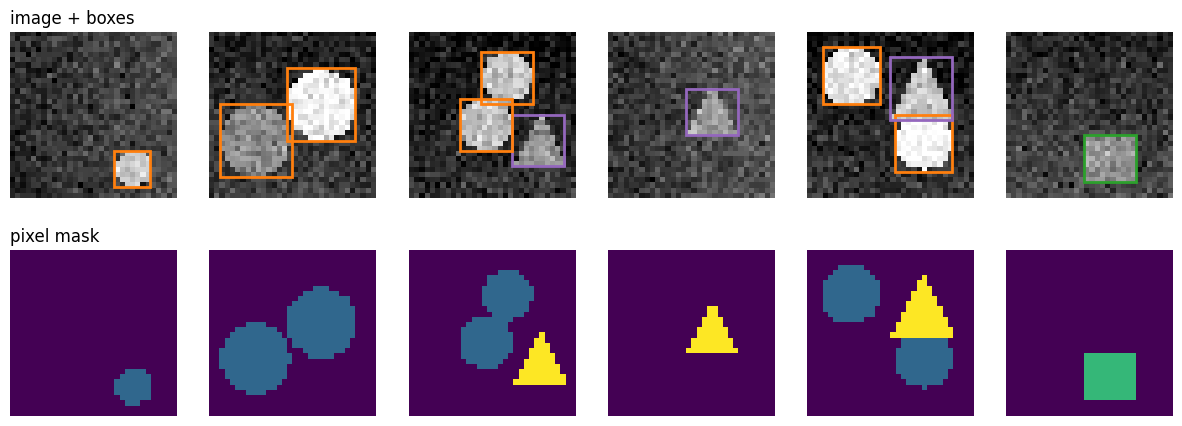

pixel share per class: {'background': '85.5%', 'circle': '5.7%', 'square': '5.1%', 'triangle': '3.7%'}


In [2]:
S = 32
CLASSES = ["background", "circle", "square", "triangle"]
yy, xx = np.mgrid[0:S, 0:S] + 0.5

def shape_mask(kind, cx, cy, r):
    if kind == 1:
        return (xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2
    if kind == 2:
        return (np.abs(xx - cx) <= r * 0.85) & (np.abs(yy - cy) <= r * 0.85)
    # upward triangle inscribed in the box [cx-r, cx+r] x [cy-r, cy+r]
    top, base = cy - r, cy + r
    half_width = r * (yy - top) / (2 * r)
    return (yy >= top) & (yy <= base) & (np.abs(xx - cx) <= half_width)

def make_scene(rng):
    img = rng.uniform(0.0, 0.25) + 0.15 * (xx / S if rng.random() < 0.5 else yy / S)     # uneven lighting
    mask = np.zeros((S, S), dtype=np.int64)
    boxes = []
    for _ in range(rng.integers(1, 4)):
        for attempt in range(20):                                   # avoid heavy overlaps
            kind, r = int(rng.integers(1, 4)), rng.uniform(3.5, 7)
            cx, cy = rng.uniform(r, S - r), rng.uniform(r, S - r)
            m = shape_mask(kind, cx, cy, r)
            if (mask[m] > 0).mean() < 0.1:
                break
        img = np.where(m, rng.uniform(0.55, 1.0), img)
        mask[m] = kind
        ys, xs = np.where(m)
        boxes.append((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1, kind))
    img = img + rng.normal(0, 0.08, img.shape)
    return img.astype(np.float32), mask, boxes

def make_dataset(n, seed):
    rng = np.random.default_rng(seed)
    data = [make_scene(rng) for _ in range(n)]
    X = torch.tensor(np.stack([d[0] for d in data])).unsqueeze(1)
    M = torch.tensor(np.stack([d[1] for d in data]))
    return X, M, [d[2] for d in data]

X_tr, M_tr, B_tr = make_dataset(3000, 0)
X_te, M_te, B_te = make_dataset(500, 1)
colors = {1: "tab:orange", 2: "tab:green", 3: "tab:purple"}

fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
for k in range(6):
    axes[0, k].imshow(X_tr[k, 0], cmap="gray", vmin=0, vmax=1)
    for x0, y0, x1, y1, c in B_tr[k]:
        axes[0, k].add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, color=colors[c], lw=2))
    axes[1, k].imshow(M_tr[k], cmap="viridis", vmin=0, vmax=3)
    axes[0, k].axis("off"); axes[1, k].axis("off")
axes[0, 0].set_title("image + boxes", loc="left"); axes[1, 0].set_title("pixel mask", loc="left")
plt.show()
print("pixel share per class:", {c: f"{(M_tr == i).float().mean().item():.1%}" for i, c in enumerate(CLASSES)})

Note the class imbalance: most pixels are background. A model that predicts "background" everywhere would already be about 80% "accurate", which is why segmentation is scored per class with **IoU** (below), not with pixel accuracy.

## 2. Semantic segmentation with a small U-Net

A classifier squeezes the image down to one vector. A segmenter must produce an output **the same size as the input**. The **U-Net** (Ronneberger et al., 2015) does both:

* an **encoder** (contracting path) of convolutions and pooling builds up *what* is in the image, at lower and lower resolution;
* a **decoder** (expanding path) of transposed convolutions grows the resolution back up, to say *where*;
* **skip connections** copy the high-resolution encoder features straight across to the decoder at the same scale, so the fine detail lost by pooling can be recovered.

```
32×32 ─conv─► e1 (16ch) ───────────────── skip ───────────────► concat ─conv─► 32×32 × 4 classes
                │ pool                                             ▲ up
               16×16 ─conv─► e2 (32ch) ─────── skip ───► concat ─conv─┘
                               │ pool                      ▲ up
                              8×8 ─conv─► bottleneck (64ch) ┘
```

A **transposed convolution** (`ConvTranspose2d`, stride 2) is the learnable opposite of pooling: each input pixel "paints" a 2×2 patch of the output with learned weights.

In [3]:
def double_conv(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                         nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU())

class UNet(nn.Module):
    def __init__(self, skips=True, n_classes=4):
        super().__init__()
        self.skips = skips
        self.e1, self.e2, self.mid = double_conv(1, 16), double_conv(16, 32), double_conv(32, 64)
        self.up2, self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2), nn.ConvTranspose2d(32, 16, 2, stride=2)
        k = 2 if skips else 1
        self.d2, self.d1 = double_conv(32 * k, 32), double_conv(16 * k, 16)
        self.out = nn.Conv2d(16, n_classes, 1)                 # 1x1 conv: a classifier at every pixel
    def forward(self, x):
        e1 = self.e1(x)                                        # 32x32
        e2 = self.e2(F.max_pool2d(e1, 2))                      # 16x16
        m = self.mid(F.max_pool2d(e2, 2))                      # 8x8
        u2 = self.up2(m)
        d2 = self.d2(torch.cat([u2, e2], 1) if self.skips else u2)
        u1 = self.up1(d2)
        d1 = self.d1(torch.cat([u1, e1], 1) if self.skips else u1)
        return self.out(d1)                                    # (batch, 4, 32, 32): class scores per pixel

def iou_per_class(pred, mask, n=4):
    return [((pred == c) & (mask == c)).sum().item() / max(1, ((pred == c) | (mask == c)).sum().item()) for c in range(n)]

def fit_seg(model, epochs=8, lr=3e-3, batch=32):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X_tr))
        for i in range(0, len(X_tr), batch):
            b = perm[i:i + batch]
            loss = F.cross_entropy(model(X_tr[b]), M_tr[b])     # cross-entropy averaged over every pixel
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        return model(X_te).argmax(1)

seg = {}
for name, skips in [("U-Net", True), ("no skip connections", False)]:
    torch.manual_seed(0)
    t0 = time.time()
    model = UNet(skips)
    pred = fit_seg(model)
    seg[name] = (model, pred)
    ious = iou_per_class(pred, M_te)
    print(f"{name:20s} params {count_params(model):,}  ({time.time() - t0:.0f}s)\n   pixel accuracy {(pred == M_te).float().mean().item():.1%}   "
          + "   ".join(f"IoU {c} {v:.2f}" for c, v in zip(CLASSES, ious)) + f"   mean IoU (objects) {np.mean(ious[1:]):.2f}")

U-Net                params 117,444  (122s)
   pixel accuracy 99.9%   IoU background 1.00   IoU circle 0.98   IoU square 0.98   IoU triangle 0.98   mean IoU (objects) 0.98


no skip connections  params 105,924  (111s)
   pixel accuracy 99.5%   IoU background 1.00   IoU circle 0.95   IoU square 0.98   IoU triangle 0.97   mean IoU (objects) 0.96


**Intersection over union** for a class is $\frac{|\text{predicted} \cap \text{true}|}{|\text{predicted} \cup \text{true}|}$: 1 is perfect, and unlike pixel accuracy it cannot be inflated by the huge background.

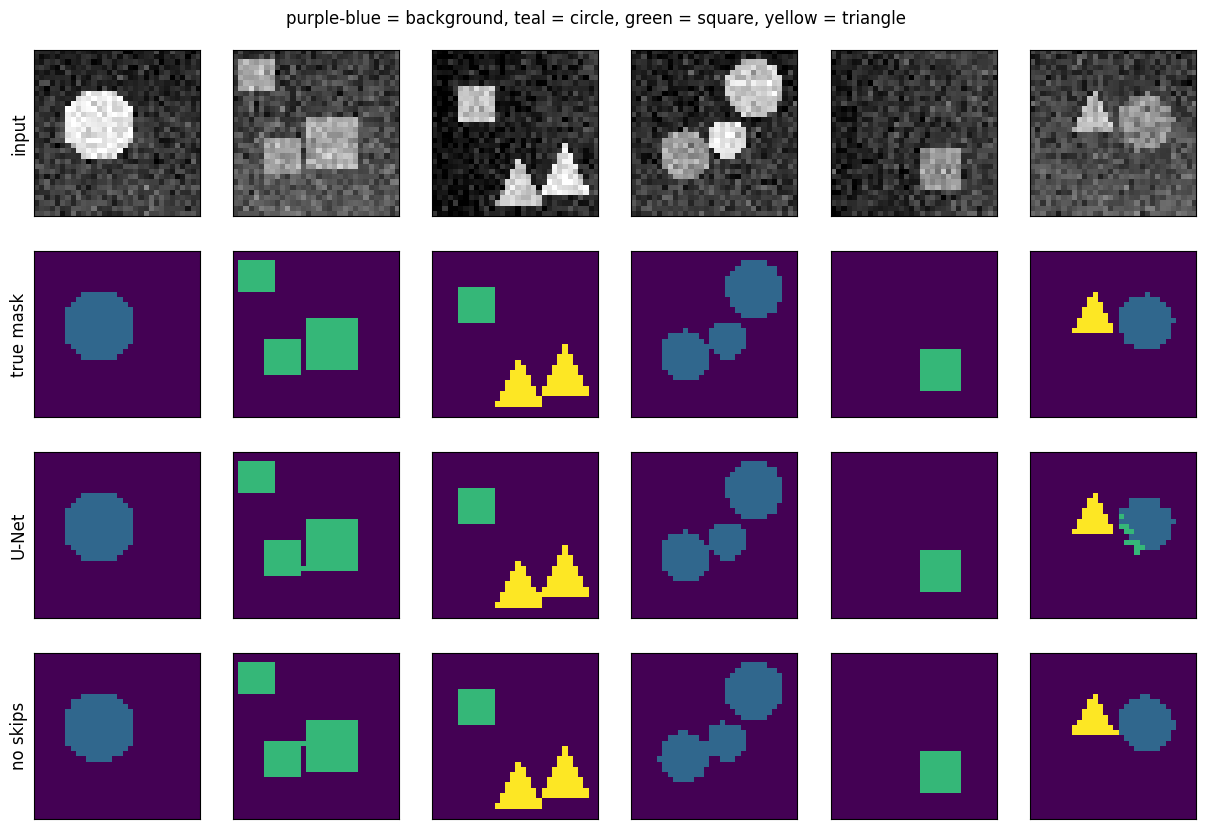

In [4]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10))
for k in range(6):
    axes[0, k].imshow(X_te[k, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, k].imshow(M_te[k], cmap="viridis", vmin=0, vmax=3)
    axes[2, k].imshow(seg["U-Net"][1][k], cmap="viridis", vmin=0, vmax=3)
    axes[3, k].imshow(seg["no skip connections"][1][k], cmap="viridis", vmin=0, vmax=3)
for ax, t in zip(axes[:, 0], ["input", "true mask", "U-Net", "no skips"]):
    ax.set_ylabel(t, fontsize=12)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("purple-blue = background, teal = circle, green = square, yellow = triangle", y=0.92); plt.show()

Both networks do well on these clean shapes; the skip connections buy a couple of IoU points, and the difference is concentrated exactly where you would expect: along boundaries, corners and triangle tips, which the no-skip decoder has to reconstruct from an 8×8 summary. With skips, the decoder knows *what* from the bottleneck and *where* from the copied high-resolution features. On real images with fine structure (blood vessels, road edges) the gap is much larger, which is why the U-Net shape became standard. The same encoder-decoder-with-skips shape is used in medical imaging, satellite mapping, and as the denoising network inside image diffusion models.

## 3. Object detection, YOLO-style

Segmentation labels pixels but does not separate two touching objects of the same class or count them. **Detection** outputs one box per object.

The **YOLO** idea ("You Only Look Once", Redmon et al., 2015) turns detection into a single regression problem. Divide the image into an $S \times S$ grid (here 4×4 cells of 8×8 pixels). The cell that contains an object's **centre** is responsible for it, and predicts:

| Output | Meaning | Loss |
|---|---|---|
| $p_{obj}$ | is there an object centred in this cell? | binary cross-entropy, every cell |
| $t_x, t_y$ | centre position inside the cell (0-1) | squared error, responsible cells only |
| $t_w, t_h$ | box width and height relative to the image | squared error on $\sqrt{\cdot}$, responsible cells only |
| class scores | circle / square / triangle | cross-entropy, responsible cells only |

So the whole network is a CNN whose output is a $4 \times 4 \times 8$ tensor. (The real YOLO adds several "anchor" boxes per cell so that one cell can hold more than one object; we keep one.)

In [5]:
G, CELL = 4, S // 4

def encode_targets(boxes_list):
    T = torch.zeros(len(boxes_list), G, G, 6)                  # obj, tx, ty, tw, th, class
    for n, boxes in enumerate(boxes_list):
        for x0, y0, x1, y1, c in boxes:
            cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
            gx, gy = min(int(cx // CELL), G - 1), min(int(cy // CELL), G - 1)
            T[n, gy, gx] = torch.tensor([1, cx / CELL - gx, cy / CELL - gy, (x1 - x0) / S, (y1 - y0) / S, c - 1])
    return T

T_tr, T_te = encode_targets(B_tr), encode_targets(B_te)
print(f"cells holding more than one object centre (cannot be represented, so ignored): "
      f"{sum(len(b) for b in B_tr) - int(T_tr[..., 0].sum())} of {sum(len(b) for b in B_tr)} training objects")

class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(double_conv(1, 16), nn.MaxPool2d(2), double_conv(16, 32), nn.MaxPool2d(2),
                                  double_conv(32, 64), nn.MaxPool2d(2), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU())
        self.head = nn.Conv2d(64, 1 + 4 + 3, 1)                # one prediction vector per grid cell
    def forward(self, x):
        return self.head(self.body(x)).permute(0, 2, 3, 1)     # (batch, 4, 4, 8)

def yolo_loss(out, T):
    obj = T[..., 0] > 0
    l_obj = F.binary_cross_entropy_with_logits(out[..., 0], T[..., 0])
    xy = torch.sigmoid(out[..., 1:3][obj]); wh = torch.sigmoid(out[..., 3:5][obj])
    l_box = F.mse_loss(xy, T[..., 1:3][obj]) + F.mse_loss(wh.sqrt(), T[..., 3:5][obj].sqrt())
    l_cls = F.cross_entropy(out[..., 5:][obj], T[..., 5][obj].long())
    return l_obj + 5 * l_box + l_cls

torch.manual_seed(0)
det = Detector()
opt = torch.optim.Adam(det.parameters(), lr=2e-3)
t0 = time.time()
for ep in range(15):
    det.train()
    perm = torch.randperm(len(X_tr))
    for i in range(0, len(X_tr), 32):
        b = perm[i:i + 32]
        loss = yolo_loss(det(X_tr[b]), T_tr[b])
        opt.zero_grad(); loss.backward(); opt.step()
print(f"detector: {count_params(det):,} params, trained in {time.time() - t0:.0f}s, final loss {loss.item():.3f}")

cells holding more than one object centre (cannot be represented, so ignored): 31 of 6002 training objects


detector: 109,688 params, trained in 95s, final loss 0.005


### From grid outputs to boxes: thresholding and non-maximum suppression

Decoding turns each confident cell back into a box in pixel coordinates. Neighbouring cells sometimes both claim the same object, so the last step is **non-maximum suppression (NMS)**: sort boxes by confidence, keep the best, delete every remaining box of the same class that overlaps it by more than an IoU threshold, repeat.

A predicted box counts as a **true positive** if it overlaps an unmatched ground-truth box of the same class with IoU ≥ 0.5.

In [6]:
def box_iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)

def decode(out, threshold=0.5, nms_iou=0.4):
    boxes = []
    p = torch.sigmoid(out[..., 0])
    for gy in range(G):
        for gx in range(G):
            if p[gy, gx] > threshold:
                tx, ty = torch.sigmoid(out[gy, gx, 1:3]).tolist(); tw, th = torch.sigmoid(out[gy, gx, 3:5]).tolist()
                cx, cy, w, h = (gx + tx) * CELL, (gy + ty) * CELL, tw * S, th * S
                boxes.append((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2, int(out[gy, gx, 5:].argmax()) + 1, p[gy, gx].item()))
    boxes.sort(key=lambda b: -b[5])
    kept = []
    for b in boxes:                                            # non-maximum suppression
        if all(k[4] != b[4] or box_iou(k, b) < nms_iou for k in kept):
            kept.append(b)
    return kept

def evaluate(threshold):
    tp = fp = 0
    n_true = sum(len(b) for b in B_te)
    det.eval()
    with torch.no_grad():
        outs = det(X_te)
    for out, truth in zip(outs, B_te):
        unmatched = list(truth)
        for b in decode(out, threshold):
            match = next((t for t in unmatched if t[4] == b[4] and box_iou(t, b) >= 0.5), None)
            if match: tp += 1; unmatched.remove(match)
            else: fp += 1
    return tp / max(1, tp + fp), tp / n_true

print(f"{'threshold':>9s} {'precision':>10s} {'recall':>8s}")
pr = []
for th in [0.9, 0.7, 0.5, 0.3, 0.1]:
    p, r = evaluate(th); pr.append((r, p))
    print(f"{th:9.1f} {p:10.1%} {r:8.1%}")

threshold  precision   recall


      0.9      98.8%    93.9%


      0.7      98.9%    95.0%


      0.5      98.9%    96.0%


      0.3      98.9%    96.8%


      0.1      98.9%    97.4%


**Precision** is the share of predicted boxes that are correct; **recall** is the share of real objects that were found. The confidence threshold trades one for the other, and detection benchmarks summarise the whole curve as *mean average precision* (mAP). Let us look at some detections:

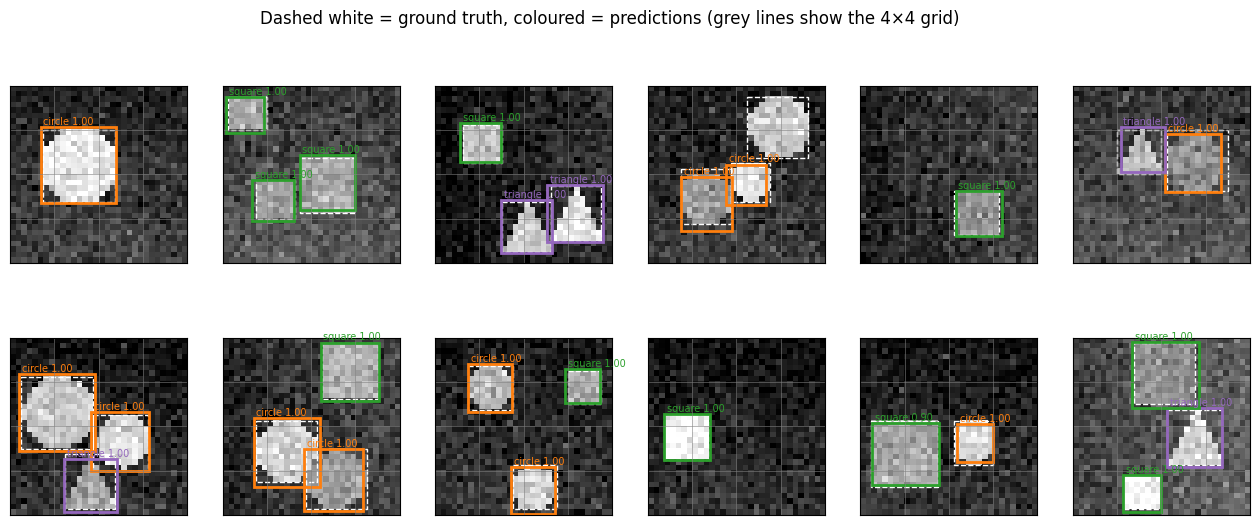

In [7]:
det.eval()
with torch.no_grad():
    outs = det(X_te[:12])
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, img, out, truth in zip(axes.ravel(), X_te[:12], outs, B_te[:12]):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    for x0, y0, x1, y1, c in truth:
        ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, color="white", lw=1, ls="--"))
    for x0, y0, x1, y1, c, conf in decode(out):
        ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, color=colors[c], lw=2))
        ax.text(x0, y0 - 1, f"{CLASSES[c]} {conf:.2f}", color=colors[c], fontsize=7)
    for k in range(1, G):
        ax.axhline(k * CELL - 0.5, color="gray", lw=0.4); ax.axvline(k * CELL - 0.5, color="gray", lw=0.4)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Dashed white = ground truth, coloured = predictions (grey lines show the 4×4 grid)"); plt.show()

One network evaluation per image gives every box at once, which is why YOLO-style detectors run in real time. Their classic weakness is visible in the encoding step: one cell can only hold one object, so small objects packed closely together are hard. Modern detectors use several anchor boxes per cell, multiple grid resolutions, and (in DETR-style models) attention instead of a grid.

## 4. Metric learning: learning what "same" means

A classifier can only output the classes it was trained on. Face recognition cannot work that way: a phone must recognise its owner from one enrolment photo, without retraining. The solution (FaceNet, Schroff et al., 2015; and earlier Siamese networks) is to learn an **embedding** $f(x)$ in which images of the same identity are close and images of different identities are far apart. Then:

* **verification**: same person if $\|f(x_1) - f(x_2)\| < \tau$;
* **recognition**: nearest enrolled embedding.

The **triplet loss** trains this directly. Take an *anchor* $a$, a *positive* $p$ (same identity) and a *negative* $n$ (different identity):

$$ \mathcal{L} = \max\big(0,\; \|f(a) - f(p)\|^2 - \|f(a) - f(n)\|^2 + \alpha\big) $$

It is zero once the negative is further away than the positive by at least the margin $\alpha$.

We use handwritten digits as stand-in "identities". The network is trained on digits **0 to 6 only**. We then test it on new images of those digits, and on **7, 8 and 9**, which it has never seen, the position a face system is in when it meets a new person.

In [8]:
from sklearn.datasets import load_digits
digits = load_digits()
Xd = torch.tensor(digits.images / 16.0, dtype=torch.float32).unsqueeze(1)
yd = torch.tensor(digits.target)
seen, unseen = yd <= 6, yd >= 7
g_split = torch.Generator().manual_seed(0)
perm = torch.randperm(int(seen.sum()), generator=g_split)
Xseen, yseen = Xd[seen][perm], yd[seen][perm]
Xs, ys = Xseen[:900], yseen[:900]                 # training images of digits 0-6
Xh, yh = Xseen[900:], yseen[900:]                 # held-out images of the SAME digits
Xu, yu = Xd[unseen], yd[unseen]                   # digits 7-9, never seen in training

class Embedder(nn.Module):
    def __init__(self, dim=16):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
                                 nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 16, 128), nn.ReLU(), nn.Linear(128, dim))
    def forward(self, x):
        return F.normalize(self.net(x), dim=1)                  # embeddings live on the unit sphere

def pk_batch(X, y, classes, P=7, K=8, gen=None):
    # P identities x K images each, so every anchor has positives and negatives in the same batch
    idx = []
    for c in classes[torch.randperm(len(classes), generator=gen)[:P]]:
        pool = (y == c).nonzero().ravel()
        idx.append(pool[torch.randint(0, len(pool), (K,), generator=gen)])
    idx = torch.cat(idx)
    return X[idx], y[idx]

def batch_hard_triplet_loss(f, y, margin):
    # for each anchor: its FARTHEST positive and its CLOSEST negative in the batch (the hardest triplet)
    D = torch.cdist(f, f).pow(2)
    same = y[:, None] == y[None, :]
    hardest_pos = (D * same).max(1).values
    hardest_neg = (D + same * 1e9).min(1).values
    return F.relu(hardest_pos - hardest_neg + margin).mean()

torch.manual_seed(0)
emb_net = Embedder()
opt = torch.optim.Adam(emb_net.parameters(), lr=1e-3)
gen = torch.Generator().manual_seed(0)
classes, t0 = torch.arange(7), time.time()
for step in range(1500):
    xb, yb = pk_batch(Xs, ys, classes, gen=gen)
    loss = batch_hard_triplet_loss(emb_net(xb), yb, margin=0.2)
    opt.zero_grad(); loss.backward(); opt.step()
print(f"trained on digits 0-6 for 1500 batches in {time.time() - t0:.0f}s, final loss {loss.item():.3f}")

trained on digits 0-6 for 1500 batches in 27s, final loss 0.000


Random triplets are mostly *easy* (a "1" and a "0" are already far apart), so they quickly stop teaching anything. **Batch-hard mining** (Hermans et al., 2017) builds each batch from a few identities with several images each, and for every anchor uses only its hardest positive and hardest negative in the batch.

Now the test, in the setting of a face-recognition system: **enrol one image per identity**, then recognise every other image by its nearest enrolled embedding. We run it twice: on new images of the digits seen in training (0-6), and on the digits the network has never seen (7-9). Raw pixels are the baseline.

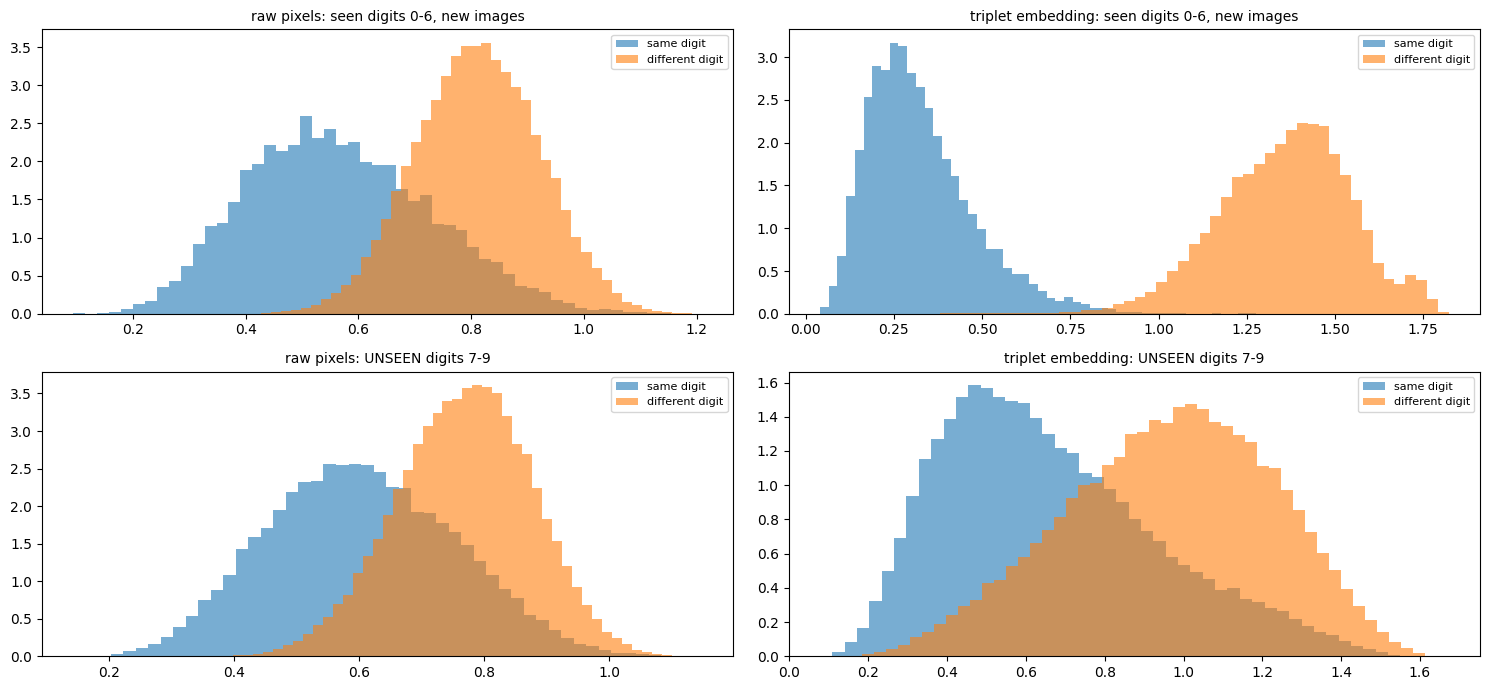

one-shot recognition from ONE enrolment image per identity
                         seen 0-6 (7-way)   unseen 7-9 (3-way)
chance                              14.3%                33.3%


raw pixels                          74.0%                73.5%


triplet embedding                   99.2%                68.2%


In [9]:
emb_net.eval()
with torch.no_grad():
    Eh, Eu = emb_net(Xh), emb_net(Xu)
pix = lambda X: F.normalize(X.flatten(1), dim=1)

def pair_distances(E, y):
    D = torch.cdist(E, E)
    same = (y[:, None] == y[None, :]) & ~torch.eye(len(y), dtype=torch.bool)
    diff = y[:, None] != y[None, :]
    return D[same].numpy(), D[diff].numpy()

def one_shot(E, y, trials=200, seed=0):
    # enrol ONE random example per identity, classify every other example by nearest enrolled embedding
    g = np.random.default_rng(seed); ids = sorted(set(y.tolist())); acc = []
    for _ in range(trials):
        refs = [g.choice(np.where(y.numpy() == d)[0]) for d in ids]
        pred = torch.tensor(ids)[torch.cdist(E, E[refs]).argmin(1)]
        mask = torch.ones(len(y), dtype=torch.bool); mask[refs] = False
        acc.append((pred[mask] == y[mask]).float().mean().item())
    return np.mean(acc)

fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for row, (label, X, y, E) in enumerate([("seen digits 0-6, new images", Xh, yh, Eh), ("UNSEEN digits 7-9", Xu, yu, Eu)]):
    for col, (name, Z) in enumerate([("raw pixels", pix(X)), ("triplet embedding", E)]):
        s, d = pair_distances(Z, y)
        ax = axes[row, col]
        ax.hist(s, bins=50, alpha=0.6, density=True, label="same digit"); ax.hist(d, bins=50, alpha=0.6, density=True, label="different digit")
        ax.set_title(f"{name}: {label}", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("one-shot recognition from ONE enrolment image per identity")
print(f"{'':22s} {'seen 0-6 (7-way)':>18s} {'unseen 7-9 (3-way)':>20s}")
print(f"{'chance':22s} {1/7:18.1%} {1/3:20.1%}")
print(f"{'raw pixels':22s} {one_shot(pix(Xh), yh):18.1%} {one_shot(pix(Xu), yu):20.1%}")
print(f"{'triplet embedding':22s} {one_shot(Eh, yh):18.1%} {one_shot(Eu, yu):20.1%}")

On the identities it was trained on, the embedding is far better than raw pixels: the "same" and "different" distances separate cleanly, and one enrolment image is enough. On the unseen digits the picture is much less flattering. Depending on the random seed, the embedding lands around the raw-pixel baseline, sometimes a little above, sometimes below (try a few seeds).

That is an honest and important result, not a bug. **Seven training identities are not enough to learn a general notion of "same".** With so few, the network learns features that separate *those seven digits* and has no reason to organise the rest of the space well. FaceNet was trained on about 8 million identities for exactly this reason: generalising to new identities is a property you buy with *diversity of identities*, not with more images of the same few. The same lesson applies to every embedding model, including the text embeddings behind retrieval-augmented generation: they work on new inputs because they were trained on an enormous variety of them.

## Key takeaways

* **Segmentation** = a classifier at every pixel. Encoder-decoder networks with **skip connections** (U-Net) recover the detail that pooling throws away. Score it with per-class **IoU**, not pixel accuracy.
* **Detection** can be framed as one regression on a grid (YOLO): objectness + box + class per cell, decoded with a threshold and **non-maximum suppression**. Precision and recall trade off through the confidence threshold.
* **Metric learning** with a triplet loss learns an embedding where distance means similarity, the basis of face verification and similarity search. Generalising to identities never seen in training requires training on *many* identities.

## Exercises

1. Train the U-Net for 2 epochs instead of 8. Which class suffers most, and why might triangles be the hardest?
2. Add a fourth shape (for example a ring: a circle with a hole) to `shape_mask` and retrain both the segmenter and the detector.
3. In the detector, change the grid to 8×8 cells of 4 pixels. How do precision and recall change, and why do small grids help crowded scenes?
4. Remove NMS from `decode` (keep every box above the threshold). How does precision change?
5. Train the triplet network with margins 0.1 and 0.5, and with three random seeds each. How stable is the one-shot accuracy on the unseen digits, compared with the seen ones?
6. Train on digits 0-4 only and test on 5-9, then on 0-7 and test on 8-9. Does unseen-identity accuracy improve as the number of training identities grows?